<div align="center">

# KECERDASAN ARTIFISIAL UNTUK GEOFISIKA

<img src="https://www.unhas.ac.id/wp-content/uploads/2022/09/Logo-Resmi-Unhas-1.png" alt="Logo Universitas Hasanuddin" width="180">

### TUGAS: STUDI KASUS PENERAPAN AI DALAM INTERPRETASI DATA GEOFISIKA

**Disusun oleh:**

**BASO MUHAMMAD ALIFKA AGNUR**  
**NIM: H061241015**

</div>

---



## Pendahuluan

Dalam pekerjaan geofisika, kecerdasan artifisial (AI) dapat digunakan sebagai pendamping untuk membantu membaca pola data, membuat visualisasi awal, merangkum indikasi bawah permukaan, dan menyusun interpretasi yang terstruktur. Hasil AI tetap harus diperiksa dengan prinsip fisika, kondisi geologi setempat, kualitas data, serta informasi pendukung lainnya.

Prompt disusun secara sistematis agar analisis memiliki batasan yang jelas. Pada tugas ini digunakan lima metode, yaitu **Geolistrik Resistivitas, Seismik, Ground Penetrating Radar (GPR), Induced Polarization (IP), dan Multichannel Analysis of Surface Waves (MASW)**.

### Kerangka prompt studi kasus

| Komponen | Keterangan |
|---|---|
| **Role** | Peran yang dijalankan AI dalam membantu analisis geofisika. |
| **Task** | Pekerjaan atau analisis yang harus dilakukan. |
| **Context** | Latar belakang dan tujuan survei. |
| **Input** | Jenis data yang tersedia sebagai masukan. |
| **Output** | Bentuk hasil yang diharapkan. |
| **Constraints** | Batasan interpretasi dan hal yang tidak boleh disimpulkan tanpa bukti. |
| **Validation** | Pemeriksaan hasil dengan teori, data lapangan, dan informasi geologi pendukung. |

# 1. STUDI KASUS GEOLISTRIK RESISTIVITAS

### Deskripsi
Studi kasus ini menggunakan penampang resistivitas 2D untuk mengidentifikasi variasi sifat kelistrikan material bawah permukaan. Zona resistivitas rendah dapat berkaitan dengan material lempung, tanah jenuh air, atau fluida yang lebih konduktif. Zona resistivitas tinggi dapat berhubungan dengan batuan kompak atau material kering, tetapi hubungan tersebut tidak bersifat tunggal.

### Prompt berbasis kerangka
- **Role:** Anda adalah pendamping interpretasi geofisika yang memahami metode resistivitas.
- **Task:** Jelaskan pola resistivitas rendah dan tinggi pada penampang serta kemungkinan kondisi geologi yang menyebabkannya.
- **Context:** Survei dilakukan untuk memperoleh gambaran awal variasi lapisan bawah permukaan.
- **Input:** Penampang resistivitas 2D dengan jarak lintasan dan kedalaman.
- **Output:** Uraian pola anomali, kemungkinan penyebab, dan rekomendasi pemeriksaan lanjutan.
- **Constraints:** Jangan menetapkan jenis batuan atau keberadaan air hanya dari nilai resistivitas.
- **Validation:** Bandingkan dengan data geologi, muka air tanah, dan hasil pengeboran jika tersedia.

### Eksekusi 1: Penampang resistivitas sintetis

Data sintetis berikut menggambarkan latar resistivitas 100 Ωm dengan satu zona resistivitas rendah di bagian tengah. Grafik hanya digunakan untuk latihan interpretasi.

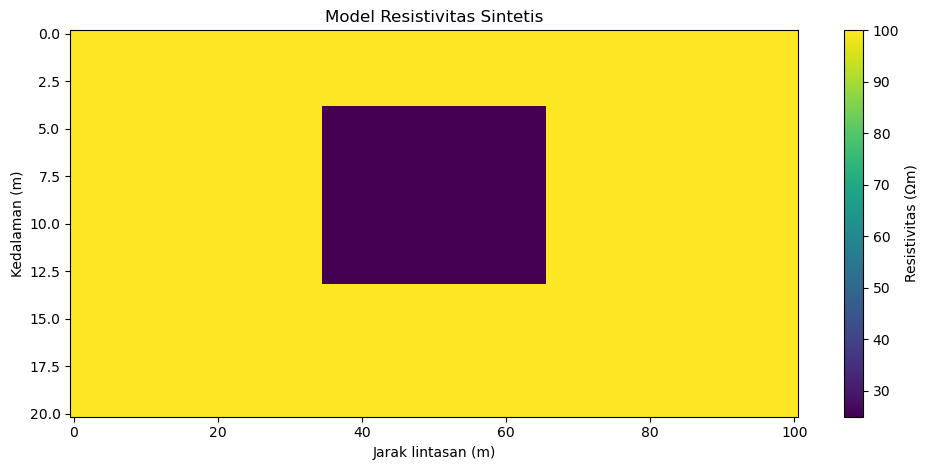

Rentang resistivitas sintetis: 25.0–100.0 Ωm


In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Membuat penampang resistivitas sintetis
x = np.linspace(0, 100, 101)       # jarak lintasan (m)
z = np.linspace(0, 20, 61)         # kedalaman (m)
X, Z = np.meshgrid(x, z)
rho = np.full_like(X, 100.0)

anomali = (X >= 35) & (X <= 65) & (Z >= 4) & (Z <= 13)
rho[anomali] = 25

plt.figure(figsize=(10, 4.8))
im = plt.pcolormesh(X, Z, rho, shading="auto", cmap="viridis")
plt.gca().invert_yaxis()
plt.xlabel("Jarak lintasan (m)")
plt.ylabel("Kedalaman (m)")
plt.title("Model Resistivitas Sintetis")
plt.colorbar(im, label="Resistivitas (Ωm)")
plt.tight_layout()
plt.show()

print(f"Rentang resistivitas sintetis: {rho.min():.1f}–{rho.max():.1f} Ωm")

**Interpretasi contoh:** Zona 25 Ωm berada pada jarak sekitar 35–65 m dan kedalaman 4–13 m, lebih rendah dibandingkan latar 100 Ωm. Anomali tersebut menunjukkan material yang lebih konduktif, tetapi penyebabnya bisa berupa lempung, peningkatan kandungan air, atau faktor lain. Diperlukan informasi pendukung untuk menentukan penyebab yang paling mungkin.

# 2. STUDI KASUS SEISMIK

### Deskripsi
Metode seismik memanfaatkan perambatan gelombang elastik di bawah permukaan. Waktu tempuh gelombang, amplitudo, dan pola refleksi atau refraksi dapat digunakan untuk mempelajari batas lapisan dan variasi sifat elastik material.

### Prompt berbasis kerangka
- **Role:** Anda adalah pendamping analisis data seismik refraksi.
- **Task:** Baca hubungan waktu tempuh gelombang pertama dengan jarak geofon dan jelaskan perubahan kemiringan kurva.
- **Context:** Survei bertujuan memperkirakan variasi kecepatan gelombang dan batas lapisan dangkal.
- **Input:** Data jarak geofon dan waktu tiba pertama.
- **Output:** Grafik waktu tempuh, estimasi kecepatan sederhana, dan penjelasan keterbatasannya.
- **Constraints:** Data sintetis bukan bukti kondisi geologi aktual; interpretasi tidak boleh dianggap unik.
- **Validation:** Periksa kualitas picking, geometri survei, dan kecocokan model dengan data lapangan.

### Eksekusi 2: Kurva waktu tempuh seismik sintetis

Contoh ini memakai dua tren waktu tempuh untuk mengilustrasikan perubahan kemiringan kurva yang dapat mengindikasikan gelombang merambat pada lapisan dengan kecepatan berbeda.

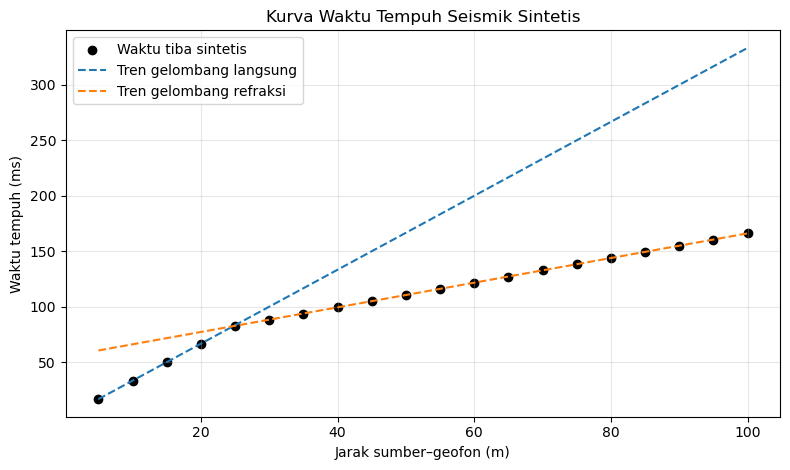

In [3]:
import numpy as np
import matplotlib.pyplot as plt

offset = np.linspace(5, 100, 20)  # jarak geofon (m)
# Data waktu tempuh sintetis: tren awal dan tren refraksi
t_direct = offset / 300.0
t_refracted = 0.055 + offset / 900.0
t_observed = np.minimum(t_direct, t_refracted)

plt.figure(figsize=(8, 4.8))
plt.scatter(offset, t_observed * 1000, label="Waktu tiba sintetis", color="black")
plt.plot(offset, t_direct * 1000, "--", label="Tren gelombang langsung")
plt.plot(offset, t_refracted * 1000, "--", label="Tren gelombang refraksi")
plt.xlabel("Jarak sumber–geofon (m)")
plt.ylabel("Waktu tempuh (ms)")
plt.title("Kurva Waktu Tempuh Seismik Sintetis")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**Interpretasi contoh:** Kurva memperlihatkan waktu tempuh yang meningkat terhadap jarak. Perubahan kemiringan dapat mencerminkan perbedaan kecepatan rambat pada model lapisan. Kecepatan dan kedalaman lapisan sebenarnya tidak boleh ditentukan hanya dari grafik ilustratif ini; dibutuhkan picking yang baik, konfigurasi akuisisi, dan analisis inversi yang sesuai.

# 3. STUDI KASUS GROUND PENETRATING RADAR (GPR)

### Deskripsi
GPR memancarkan gelombang elektromagnetik berfrekuensi tinggi ke dalam tanah dan merekam pantulannya. Radargram dapat memperlihatkan reflektor berlapis, gangguan refleksi, dan pola hiperbola yang mungkin berhubungan dengan objek lokal atau perubahan material dangkal.

### Prompt berbasis kerangka
- **Role:** Anda adalah pendamping interpretasi radargram GPR.
- **Task:** Identifikasi reflektor relatif kontinu dan anomali berbentuk hiperbola pada radargram.
- **Context:** Survei ditujukan untuk memetakan struktur atau objek dangkal.
- **Input:** Radargram dengan sumbu jarak dan waktu tempuh dua arah.
- **Output:** Deskripsi pola refleksi dan lokasi yang perlu diperiksa.
- **Constraints:** Jangan langsung menyebut anomali sebagai pipa, rongga, atau benda tertentu tanpa bukti tambahan.
- **Validation:** Pertimbangkan jenis tanah, kadar air, frekuensi antena, dan kecepatan gelombang elektromagnetik.

### Eksekusi 3: Radargram sintetis

Radargram contoh ini berisi reflektor berlapis dan satu pola hiperbola buatan. Waktu ditampilkan dalam nanodetik (ns).

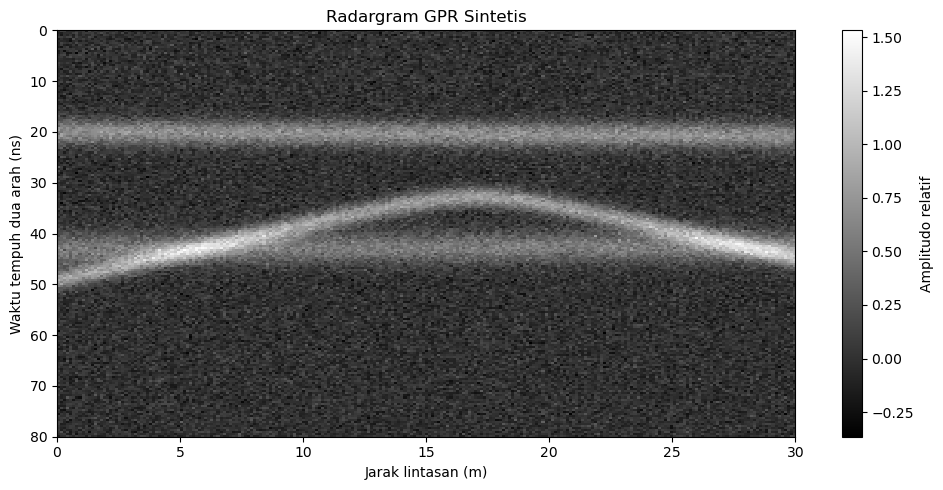

In [4]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(0, 30, 241)
t = np.linspace(0, 80, 201)
X, T = np.meshgrid(x, t)
rng = np.random.default_rng(11)
radar = 0.10 * rng.normal(size=X.shape)
radar += 0.7 * np.exp(-((T - 20 - 0.025*X)**2) / (2*1.8**2))
radar += 0.55 * np.exp(-((T - 43 + 0.015*X)**2) / (2*2.2**2))
hyperbola = 30 + 2.8 * np.sqrt(1 + ((X - 17)/2.5)**2)
radar += 0.8 * np.exp(-((T - hyperbola)**2) / (2*1.4**2))

plt.figure(figsize=(10, 5))
plt.imshow(radar, extent=[x.min(), x.max(), t.max(), t.min()],
           aspect="auto", cmap="gray", interpolation="nearest")
plt.xlabel("Jarak lintasan (m)")
plt.ylabel("Waktu tempuh dua arah (ns)")
plt.title("Radargram GPR Sintetis")
plt.colorbar(label="Amplitudo relatif")
plt.tight_layout()
plt.show()

**Interpretasi contoh:** Reflektor relatif mendatar tampak sekitar 20 ns dan 43 ns, sementara pola melengkung tampak di sekitar jarak 17 m. Reflektor dapat berkaitan dengan batas material, sedangkan hiperbola dapat muncul dari objek lokal atau heterogenitas. Kedalaman tidak dapat ditentukan langsung dari waktu tanpa estimasi kecepatan gelombang elektromagnetik.

# 4. STUDI KASUS INDUCED POLARIZATION (IP)

### Deskripsi
Metode Induced Polarization (IP) mengukur respons polarisasi material bawah permukaan setelah arus listrik diberikan. Parameter yang umum digunakan adalah *chargeability* (kemampuan material menyimpan muatan sementara) dan, pada sistem tertentu, resistivitas. IP sering digunakan untuk membantu mengenali zona yang dapat mengandung mineral terdiseminasi, tetapi respons juga dipengaruhi oleh lempung, porositas, dan kondisi elektrokimia.

### Prompt berbasis kerangka
- **Role:** Anda adalah pendamping interpretasi data IP.
- **Task:** Jelaskan distribusi chargeability dan bandingkan dengan pola resistivitas bila tersedia.
- **Context:** Survei dilakukan untuk mencari zona dengan respons polarisasi yang berbeda dari batuan sekitarnya.
- **Input:** Penampang chargeability dalam mV/V atau satuan yang digunakan instrumen.
- **Output:** Uraian anomali, kemungkinan penyebab, dan langkah validasi.
- **Constraints:** Anomali chargeability tinggi tidak otomatis membuktikan adanya bijih logam.
- **Validation:** Integrasikan dengan resistivitas, pemetaan geologi, geokimia, dan/atau pengeboran.

### Eksekusi 4: Penampang chargeability sintetis

Model ilustratif menunjukkan latar chargeability rendah dengan satu anomali lebih tinggi di bagian tengah.

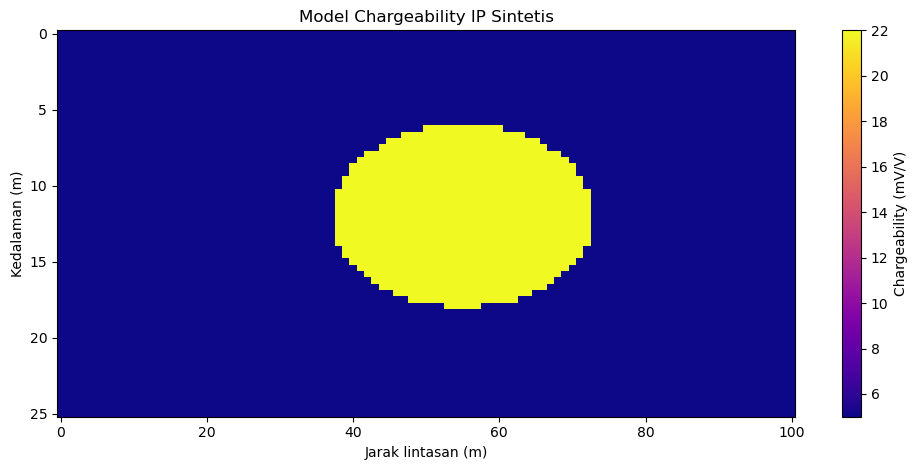

Rentang chargeability sintetis: 5.0–22.0 mV/V


In [5]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(0, 100, 101)
z = np.linspace(0, 25, 61)
X, Z = np.meshgrid(x, z)
chargeability = np.full_like(X, 5.0)  # mV/V
zone = ((X - 55)/18)**2 + ((Z - 12)/6)**2 <= 1
chargeability[zone] = 22.0

plt.figure(figsize=(10, 4.8))
im = plt.pcolormesh(X, Z, chargeability, shading="auto", cmap="plasma")
plt.gca().invert_yaxis()
plt.xlabel("Jarak lintasan (m)")
plt.ylabel("Kedalaman (m)")
plt.title("Model Chargeability IP Sintetis")
plt.colorbar(im, label="Chargeability (mV/V)")
plt.tight_layout()
plt.show()
print(f"Rentang chargeability sintetis: {chargeability.min():.1f}–{chargeability.max():.1f} mV/V")

**Interpretasi contoh:** Model memperlihatkan anomali chargeability sekitar 22 mV/V pada zona tengah, sedangkan latar bernilai 5 mV/V. Zona ini memiliki respons polarisasi relatif lebih tinggi dan layak ditinjau lebih lanjut. Interpretasi sebagai mineralisasi memerlukan bukti pendukung karena lempung dan faktor geologi lain juga dapat menghasilkan respons IP.

# 5. STUDI KASUS MULTICHANNEL ANALYSIS OF SURFACE WAVES (MASW)

### Deskripsi
MASW menganalisis gelombang permukaan yang direkam oleh banyak geofon untuk memperoleh kurva dispersi dan memperkirakan profil kecepatan gelombang geser (Vs) terhadap kedalaman. Nilai Vs berkaitan dengan kekakuan material, tetapi penentuan kondisi tanah harus mempertimbangkan kualitas data dan hasil inversi.

### Prompt berbasis kerangka
- **Role:** Anda adalah pendamping interpretasi hasil MASW.
- **Task:** Jelaskan kurva dispersi dan profil Vs, terutama perubahan kecepatan terhadap kedalaman.
- **Context:** Survei dilakukan untuk mengetahui variasi kekakuan lapisan tanah dangkal.
- **Input:** Kurva dispersi frekuensi–kecepatan fase dan/atau profil Vs hasil inversi.
- **Output:** Deskripsi lapisan dengan Vs berbeda serta catatan keterbatasan.
- **Constraints:** Jangan menyimpulkan jenis tanah secara pasti hanya berdasarkan Vs.
- **Validation:** Periksa kualitas kurva dispersi, rentang frekuensi, model inversi, dan data geoteknik pendukung.

### Eksekusi 5: Kurva dispersi dan profil Vs sintetis

Grafik berikut memperlihatkan contoh hubungan frekuensi dengan kecepatan fase serta model Vs sederhana sebagai ilustrasi pembelajaran.

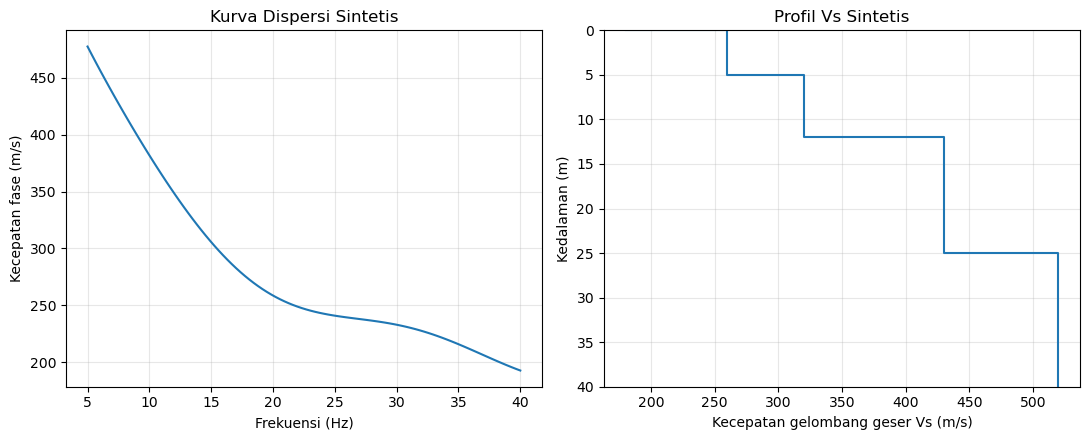

In [6]:
import numpy as np
import matplotlib.pyplot as plt

frequency = np.linspace(5, 40, 100)  # Hz
phase_velocity = 180 + 420*np.exp(-frequency/13) + 12*np.sin(frequency/4)

depth = np.array([0, 5, 12, 25, 40])
vs = np.array([180, 260, 320, 430, 520])  # m/s, model sintetis

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(frequency, phase_velocity)
axes[0].set_xlabel("Frekuensi (Hz)")
axes[0].set_ylabel("Kecepatan fase (m/s)")
axes[0].set_title("Kurva Dispersi Sintetis")
axes[0].grid(alpha=0.3)

axes[1].step(vs, depth, where="post")
axes[1].set_ylim(40, 0)
axes[1].set_xlabel("Kecepatan gelombang geser Vs (m/s)")
axes[1].set_ylabel("Kedalaman (m)")
axes[1].set_title("Profil Vs Sintetis")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Interpretasi contoh:** Model memperlihatkan Vs yang meningkat dari sekitar 180 m/s di dekat permukaan menjadi 520 m/s pada kedalaman lebih besar. Kenaikan Vs dapat menunjukkan material yang semakin kaku atau kompak. Namun, angka tersebut merupakan model sintetis; pada survei nyata, profil Vs harus diperoleh melalui inversi kurva dispersi dan dievaluasi bersama informasi geologi atau geoteknik.